# H1 Emocje negatywne w fazach cyklu

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import CYCLES, PHASE_COLORS, PHASE_ORDER, PHASES, POLITICAL_SUBREDDITS, PROCESSED_DIR, REFERENCE_SUBREDDITS, RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VARIABLE = "negative"

## 2. Wczytanie danych tygodniowych

In [2]:
weekly = pd.read_csv(PROCESSED_DIR / "weekly_emotions.csv", parse_dates=["week_start"])
weekly.shape

(2825, 18)

## 3. Średnia i mediana tygodniowa w fazach

In [3]:
phase_stats = (weekly.dropna(subset=["phase"]).groupby(["camp", "subreddit", "cycle", "phase"])[VARIABLE]
               .agg(mean="mean", median="median", n_weeks="size").reset_index())
phase_stats.to_csv(RESULTS_DIR / "h1_phase_stats.csv", index=False)
phase_stats[phase_stats["subreddit"].isin(POLITICAL_SUBREDDITS)].head(10)

,camp,subreddit,cycle,phase,mean,median,n_weeks
0,dem,Liberal,2012,bazowa,0.435085,0.420744,12
1,dem,Liberal,2012,powyborcza,0.429208,0.429561,8
2,dem,Liberal,2012,przedwyborcza,0.431213,0.433469,64
3,dem,Liberal,2012,przejsciowa,0.418918,0.421152,11
4,dem,Liberal,2012,szczytowa,0.398405,0.404057,9
5,dem,Liberal,2016,bazowa,0.401225,0.400056,19
6,dem,Liberal,2016,powyborcza,0.442225,0.437323,8
7,dem,Liberal,2016,przedwyborcza,0.425319,0.425198,50
8,dem,Liberal,2016,przejsciowa,0.434941,0.433020,11
9,dem,Liberal,2016,szczytowa,0.445765,0.445045,16


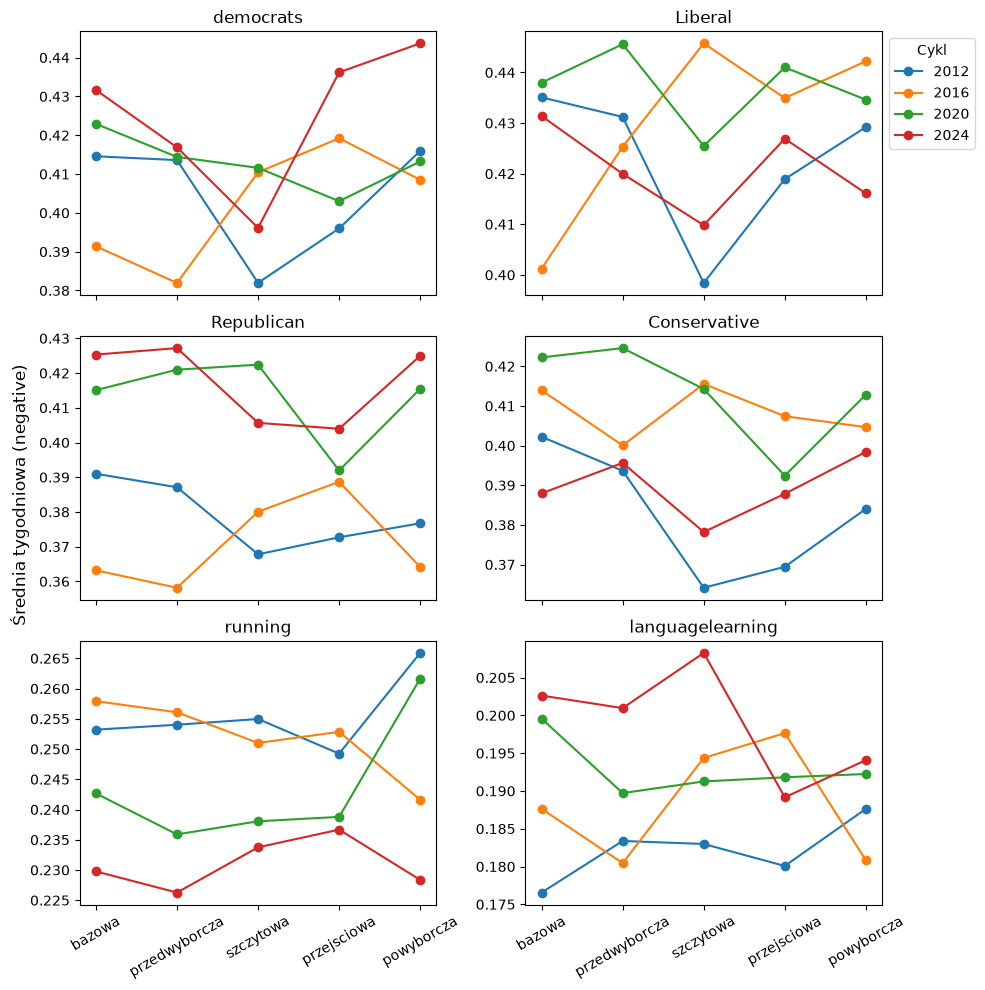

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS):
    for cycle in CYCLES:
        rows = phase_stats[(phase_stats["subreddit"] == subreddit) & (phase_stats["cycle"] == cycle)].set_index("phase").loc[PHASE_ORDER]
        ax.plot(PHASE_ORDER, rows["mean"], marker="o", label=cycle)
    ax.set_title(subreddit)
    ax.tick_params(axis="x", labelrotation=30)
axes[0, 1].legend(title="Cykl", loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Średnia tygodniowa ({VARIABLE})")
plt.tight_layout()
plt.show()

## 4. Różnica względem fazy bazowej

In [5]:
baseline = phase_stats[phase_stats["phase"] == "bazowa"].set_index(["subreddit", "cycle"])[["mean", "median"]]
diff = phase_stats.join(baseline, on=["subreddit", "cycle"], rsuffix="_baseline")
diff["diff_mean"] = diff["mean"] - diff["mean_baseline"]
diff["diff_median"] = diff["median"] - diff["median_baseline"]
diff = diff[diff["phase"].isin(PHASE_ORDER) & (diff["phase"] != "bazowa")]
diff.to_csv(RESULTS_DIR / "h1_diff_vs_baseline.csv", index=False)
diff_by_phase = diff.pivot_table(index=["subreddit", "cycle"], columns="phase", values="diff_mean")[PHASE_ORDER[1:]].loc[POLITICAL_SUBREDDITS]
diff_by_phase.round(4)

phase               przedwyborcza  szczytowa  przejsciowa  powyborcza
subreddit    cycle                                                   
democrats    2012         -0.0010    -0.0326      -0.0186      0.0014
             2016         -0.0094     0.0191       0.0278      0.0171
             2020         -0.0085    -0.0113      -0.0199     -0.0097
             2024         -0.0148    -0.0355       0.0046      0.0120
Liberal      2012         -0.0039    -0.0367      -0.0162     -0.0059
             2016          0.0241     0.0445       0.0337      0.0410
             2020          0.0076    -0.0125       0.0030     -0.0034
             2024         -0.0114    -0.0216      -0.0045     -0.0153
Republican   2012         -0.0039    -0.0232      -0.0183     -0.0143
             2016         -0.0050     0.0169       0.0255      0.0010
             2020          0.0059     0.0073      -0.0231      0.0004
             2024          0.0019    -0.0197      -0.0214     -0.0004
Conservative 2012         -0.0086    -0.0381      -0.0328     -0.0182
             2016         -0.0139     0.0016      -0.0065     -0.0093
             2020          0.0023    -0.0080      -0.0298     -0.0094
             2024          0.0077    -0.0097      -0.0001      0.0104

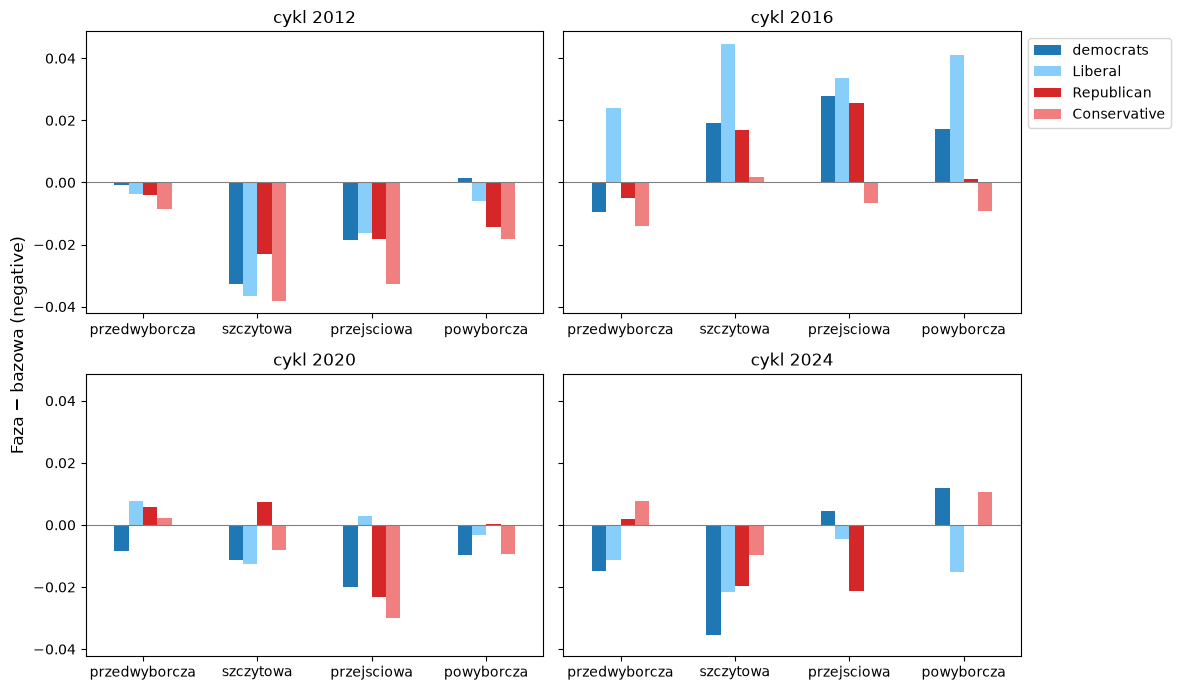

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, cycle in zip(axes.ravel(), CYCLES):
    diff_by_phase.xs(cycle, level="cycle").T.plot.bar(ax=ax, rot=0, legend=False, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral"])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"cykl {cycle}")
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Faza − bazowa ({VARIABLE})")
plt.tight_layout()
plt.show()

## 5. Faza przedwyborcza osobno dla każdego cyklu

In [7]:
pre_election = diff[diff["phase"] == "przedwyborcza"].pivot_table(index=["camp", "subreddit"], columns="cycle", values="diff_mean")
pre_election.round(4)

cycle                         2012    2016    2020    2024
camp      subreddit                                       
dem       Liberal          -0.0039  0.0241  0.0076 -0.0114
          democrats        -0.0010 -0.0094 -0.0085 -0.0148
reference languagelearning  0.0068 -0.0072 -0.0098 -0.0017
          running           0.0008 -0.0018 -0.0068 -0.0035
rep       Conservative     -0.0086 -0.0139  0.0023  0.0077
          Republican       -0.0039 -0.0050  0.0059  0.0019

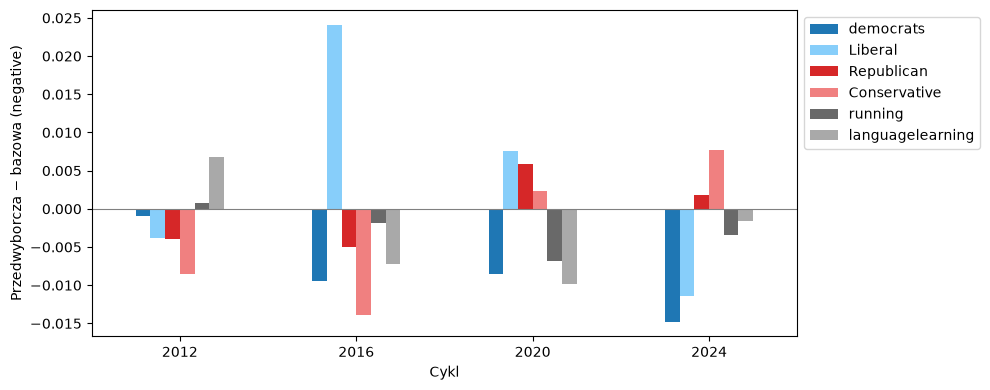

In [8]:
ax = (pre_election.droplevel("camp").loc[POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS].T
      .plot.bar(figsize=(10, 4), rot=0, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral", "dimgray", "darkgray"]))
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Cykl")
ax.set_ylabel(f"Przedwyborcza − bazowa ({VARIABLE})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 6. Subreddity odniesienia a subreddity polityczne

In [9]:
comparison = diff.groupby(["cycle", "phase", "camp"])["diff_mean"].mean().unstack("camp")
comparison["political_minus_reference"] = (comparison["dem"] + comparison["rep"]) / 2 - comparison["reference"]
comparison.to_csv(RESULTS_DIR / "h1_political_vs_reference.csv")
comparison.round(4)

camp                    dem  reference     rep  political_minus_reference
cycle phase                                                              
2012  powyborcza    -0.0022     0.0119 -0.0162                    -0.0211
      przedwyborcza -0.0024     0.0038 -0.0062                    -0.0081
      przejsciowa   -0.0174    -0.0002 -0.0255                    -0.0212
      szczytowa     -0.0346     0.0041 -0.0306                    -0.0367
2016  powyborcza     0.0291    -0.0116 -0.0042                     0.0240
      przedwyborcza  0.0073    -0.0045 -0.0095                     0.0034
      przejsciowa    0.0308     0.0025  0.0095                     0.0177
      szczytowa      0.0318    -0.0001  0.0092                     0.0206
2020  powyborcza    -0.0065     0.0058 -0.0045                    -0.0114
      przedwyborcza -0.0005    -0.0083  0.0041                     0.0101
      przejsciowa   -0.0084    -0.0058 -0.0265                    -0.0116
      szczytowa     -0.0119    -0.0065 -0.0003                     0.0003
2024  powyborcza    -0.0016    -0.0050  0.0050                     0.0067
      przedwyborcza -0.0131    -0.0026  0.0048                    -0.0016
      przejsciowa    0.0000    -0.0033 -0.0107                    -0.0021
      szczytowa     -0.0285     0.0048 -0.0147                    -0.0264

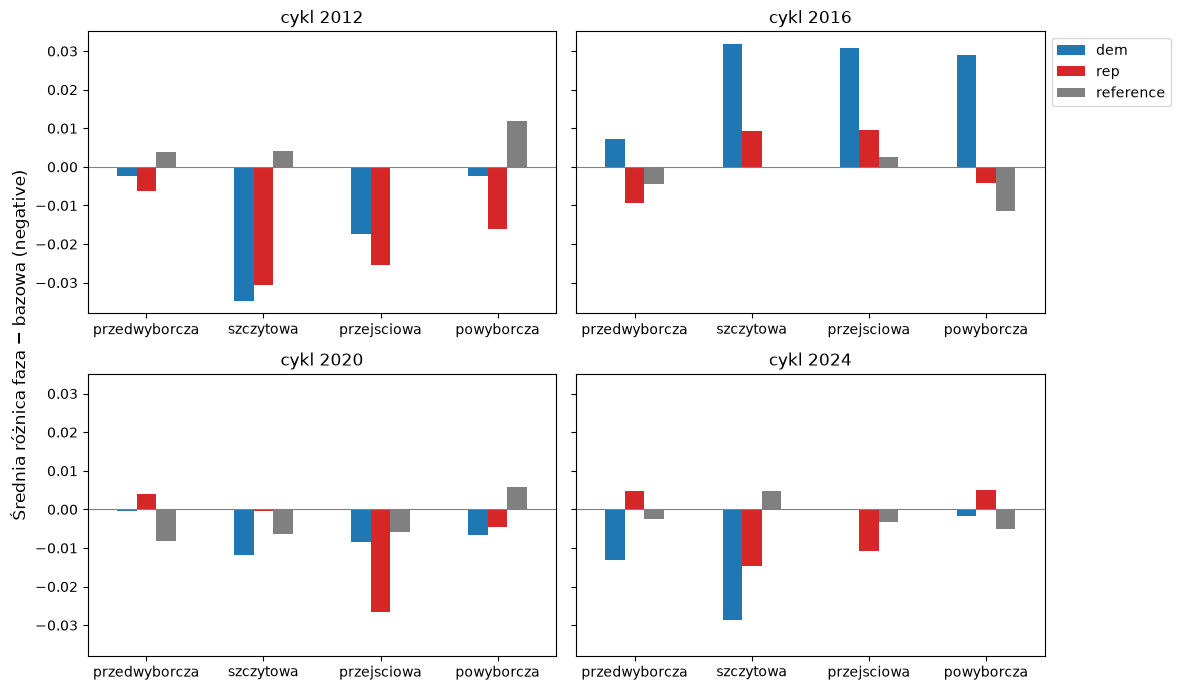

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, cycle in zip(axes.ravel(), CYCLES):
    (comparison.xs(cycle, level="cycle").loc[PHASE_ORDER[1:], ["dem", "rep", "reference"]]
     .plot.bar(ax=ax, rot=0, legend=False, color=["tab:blue", "tab:red", "gray"]))
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"cykl {cycle}")
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Średnia różnica faza − bazowa ({VARIABLE})")
plt.tight_layout()
plt.show()

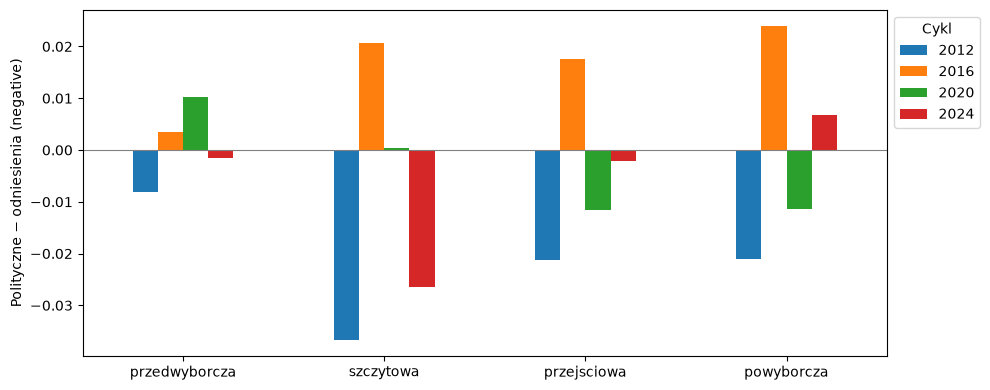

In [11]:
ax = comparison["political_minus_reference"].unstack("cycle").loc[PHASE_ORDER[1:]].plot.bar(figsize=(10, 4), rot=0)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("")
ax.set_ylabel(f"Polityczne − odniesienia ({VARIABLE})")
ax.legend(title="Cykl", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [12]:
reference_years = phase_stats[phase_stats["phase"] == "rok_referencyjny"]
reference_years.to_csv(RESULTS_DIR / "h1_reference_years.csv", index=False)
reference_means = reference_years.pivot_table(index="subreddit", columns="cycle", values="mean")
reference_means.round(4)

cycle,2014,2018,2022
subreddit,,,
languagelearning,0.1869,0.1865,0.1992
running,0.2442,0.2390,0.2341


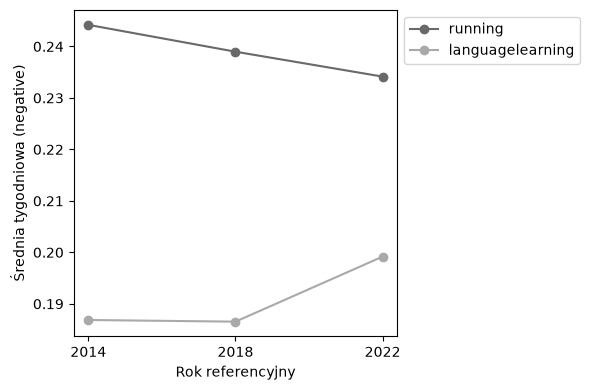

In [13]:
ax = reference_means.loc[REFERENCE_SUBREDDITS].T.plot(marker="o", figsize=(6, 4), color=["dimgray", "darkgray"])
ax.set_xticks(reference_means.columns)
ax.set_xlabel("Rok referencyjny")
ax.set_ylabel(f"Średnia tygodniowa ({VARIABLE})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 7. Wykres roboczy: tydzień po tygodniu z fazami

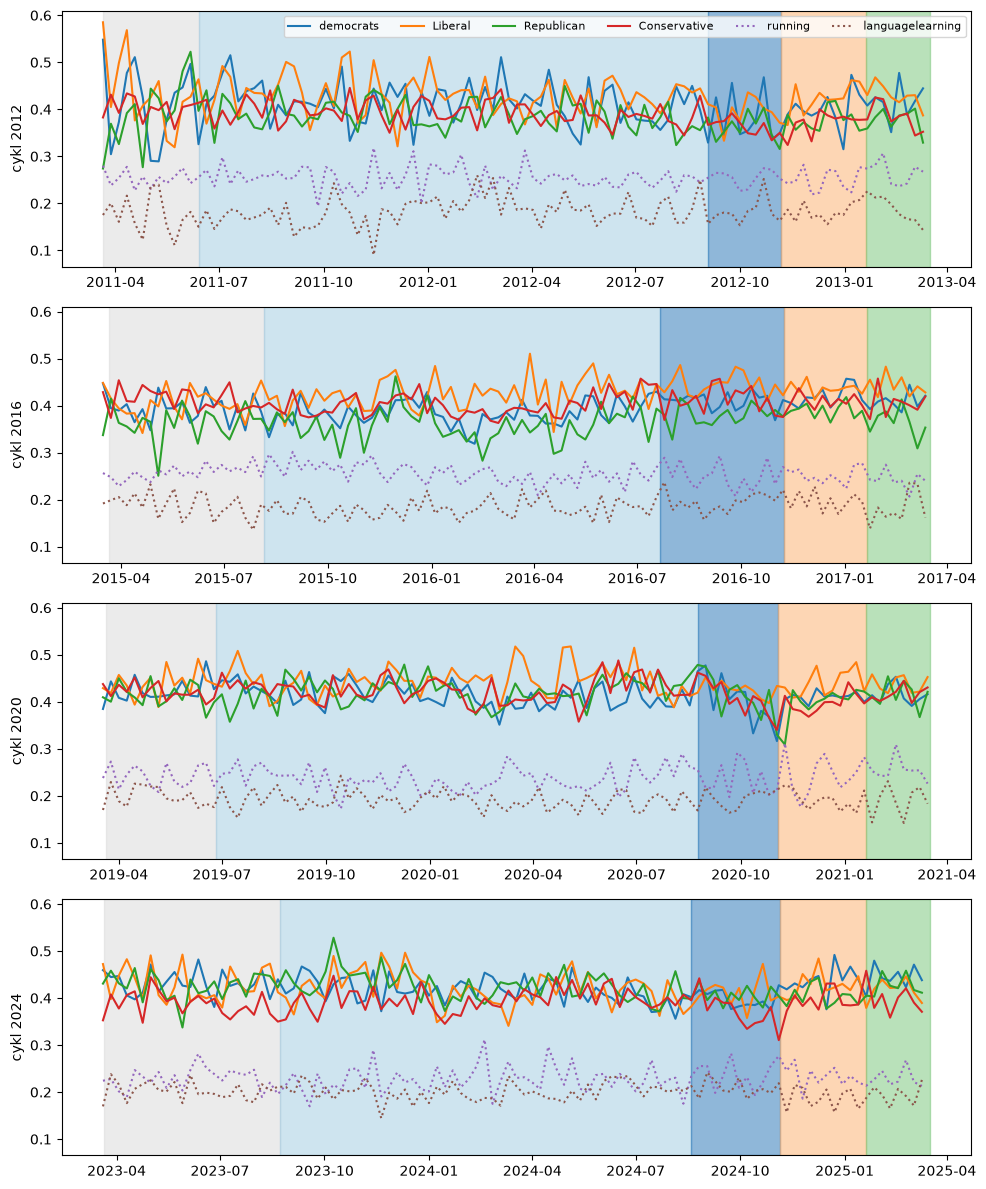

In [14]:
fig, axes = plt.subplots(len(CYCLES), 1, figsize=(10, 12), sharey=True)
for ax, cycle in zip(axes, CYCLES):
    for phase, start, end in PHASES[cycle]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), color=PHASE_COLORS[phase], alpha=0.5)
    for subreddit in POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS:
        rows = weekly[(weekly["subreddit"] == subreddit) & (weekly["cycle"] == cycle)]
        ax.plot(rows["week_start"], rows[VARIABLE], label=subreddit, linestyle="-" if subreddit in POLITICAL_SUBREDDITS else ":")
    ax.set_ylabel(f"cykl {cycle}")
axes[0].legend(ncol=6, fontsize=8)
plt.tight_layout()
plt.show()